# IS630: Green Light for an Indie Studio
## Notebook 06: AQ5, How Does the Number of Player Reviews Affect the Reliability of Estimated Player Reception?
**Group**: [Insert names]

> **AI Coding Assistant Declaration**:
> An AI coding assistant wrote the code in this notebook at the group's direction. The bar chart of interval width by review band in section 1 follows Diya Mabel Francis's AQ5 notebook. Every code section is labelled with its provenance. All interpretations, evaluations and conclusions are written by group members in the designated cells.

**AQ5** (group wording): *How does the number of player reviews affect the reliability of estimated player reception?*

Player reception is the Steam positive review rate: positive reviews over all reviews. A rate from 12 reviews and a rate from 12,000 are both reported as a single percentage. The notebook looks at review count in two ways, using methods from an introductory statistics course:

- **Reliability** (sections 2 to 5): how far one game's rate can be trusted, and how that depends on its number of reviews.
- **Level** (section 6): whether games with more reviews also have higher or lower rates, which matters when comparing games across review counts.

The sections follow the usual course order: sampling distribution, confidence interval, test for two groups, test for many groups.

| Section | Question | Method |
|---|---|---|
| 1 | What does the sample look like? | Descriptive statistics by review band |
| 2 | How does the rate vary from sample to sample? | Central limit theorem, standard error, margin of error |
| 3 | How precise is one game's rate? | 95% Wilson confidence interval |
| 4 | Can two games' rates be told apart? | Two-proportion z-test |
| 5 | How much of the spread between games is sampling noise? | Observed variance against sampling variance |
| 6 | Does the mean rate differ by review count? | Welch's ANOVA, Kruskal-Wallis, two-way ANOVA with game age |
| 7 | Answer to AQ5 | Written by the group |

**Reads:** `data/processed/02_train.parquet`, `data/processed/02_validation.parquet`, `data/processed/02_feature_spec.json`
**Writes:** tables `outputs/tables/06_aq5_*.csv`, figures `outputs/figures/06_aq5_*.png`

No model is fitted or selected here, so the development and validation splits from notebook 02 are used together: the whole training split. The test holdout from notebook 00 is never loaded.

## Why the positive review rate and not the completion ratio
*Written by AI Assistant*

AQ2 to AQ4 model the completion ratio, the metric chosen in AQ1. AQ5 studies the positive review rate instead.

**The positive rate is a common metric.** It is the review score Steam shows on a game's store page, and it is a figure players and studios often use to judge how well a game was received. The group wants to examine its properties: how far a single game's rate can be trusted, and how that depends on the number of reviews behind it. A studio that reads or quotes this number needs to know how much it can carry.

**A bonus: its mathematical properties.** A game's rate is $k$ positive reviews out of $n$, so the review count is exactly the sample size behind it. Each review is a yes or no, which makes the rate a binomial proportion. That lets this notebook use standard methods directly: the standard error $\sqrt{p(1-p)/n}$ from the central limit theorem, the Wilson interval, the margin-of-error formula, the two-proportion z-test, and the split of spread into sampling noise and real difference.

**The completion ratio does not have this structure.** It is SteamSpy's median playtime divided by the HowLongToBeat main-story time, and neither part is built from reviews:

| Part | Source | Sample size behind it |
|---|---|---|
| Numerator: median playtime | SteamSpy, inferred from public Steam profiles | Unknown. Review count is only a loose stand-in for it, so no standard error can be computed. |
| Denominator: main-story hours | HowLongToBeat player reports | The main-story poll count (`hltb_main_story_polled`), not reviews |

So the number of reviews does not set the completion ratio's precision in a way that can be calculated. The uncertainty that can be measured, on the denominator, is already handled in AQ2: the models weight each game's noise by its HowLongToBeat poll count. Notebook 01, section 3, shows how the share of zero ratios and the spread of the log ratio change with review count and poll count, as a description.

AQ5 therefore asks the reliability question about the metric people commonly use, which is also the one where the answer can be worked out from the review count.

### The group's reasons
**Author**:
<!-- Add anything the group wants to say about this choice in its own words: for example, how a studio uses the Steam review score in practice, what reception tells a studio that the completion ratio does not, and how the AQ5 findings relate to the completion ratio used in AQ2 to AQ4. -->

## Setup
*Code: Generated by AI Assistant*

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import pingouin as pg
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.proportion import proportion_confint, proportions_ztest

sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists()) / "src"))
from is630 import config

for d in (config.FIGURES, config.TABLES):
    d.mkdir(parents=True, exist_ok=True)
for stale in [*config.FIGURES.glob("06_aq5_*.png"), *config.TABLES.glob("06_aq5_*.csv")]:
    stale.unlink()  # clear this notebook's outputs so they match the current run
pd.set_option("display.width", 200)
rng = np.random.default_rng(config.SEED)

def save_fig(fig, name):
    # Write a figure to outputs/figures at 300 dpi.
    fig.savefig(config.FIGURES / f"{name}.png", dpi=300, bbox_inches="tight")

df_train = pd.read_parquet(config.PROCESSED / "02_train.parquet")
df_val = pd.read_parquet(config.PROCESSED / "02_validation.parquet")
assert set(df_train["steam_appid"]).isdisjoint(df_val["steam_appid"])
with open(config.PROCESSED / "02_feature_spec.json", encoding="utf-8") as f:
    MIN_REVIEWS = json.load(f)["inclusion_thresholds"]["min_reviews_reception"]
df = pd.concat([df_train, df_val], ignore_index=True)
print(f"rows in: {len(df):,} games in the training split ({len(df_train):,} development + {len(df_val):,} validation)")
print(f"reception threshold from notebook 02: {MIN_REVIEWS} reviews")

rows in: 5,281 games in the training split (4,224 development + 1,057 validation)
reception threshold from notebook 02: 10 reviews


## 1. The sample and the raw positive rate
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the sample is every game with `flag_reception_model`, the minimum review count fixed in notebook 02. A game's raw positive rate is $\hat p = k / n$, positive reviews $k$ over all reviews $n$. Games are grouped into five review-count bands, used throughout the notebook. Review counts grow with a game's age and audience, so the bands also differ in those.

rows out (reception sample, at least 10 reviews): 5,144


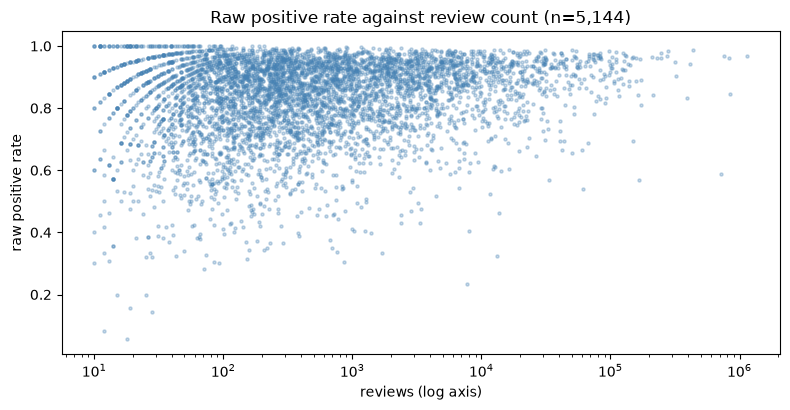

,games,median_reviews,mean_raw_rate,median_raw_rate,sd_raw_rate
band,,,,,
10-49,666,29.0,0.809,0.857,0.167
50-199,1274,106.0,0.813,0.847,0.140
200-999,1521,409.0,0.834,0.861,0.119
"1,000-9,999",1226,2611.5,0.857,0.885,0.105
"10,000+",457,24310.0,0.883,0.911,0.094


In [2]:
BANDS = [MIN_REVIEWS, 50, 200, 1000, 10000, np.inf]
BAND_LABELS = [f"{MIN_REVIEWS}-49", "50-199", "200-999", "1,000-9,999", "10,000+"]

games = df[df["flag_reception_model"]].copy()
games["n"] = games["steam_review_count"].astype(int)
games["k"] = games["steam_positive"].astype(int)
assert (games["n"] == games["steam_positive"] + games["steam_negative"]).all()
assert games["n"].ge(MIN_REVIEWS).all() and games["k"].le(games["n"]).all()
games["raw_rate"] = games["k"] / games["n"]
games["band"] = pd.cut(games["n"], BANDS, labels=BAND_LABELS, right=False)
print(f"rows out (reception sample, at least {MIN_REVIEWS} reviews): {len(games):,}")

band_table = games.groupby("band", observed=True).agg(
    games=("n", "size"), median_reviews=("n", "median"), mean_raw_rate=("raw_rate", "mean"),
    median_raw_rate=("raw_rate", "median"), sd_raw_rate=("raw_rate", "std"))
band_table.to_csv(config.TABLES / "06_aq5_raw_rate_by_band.csv")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(games["n"], games["raw_rate"], s=5, alpha=0.3, color="steelblue")
ax.set_xscale("log"); ax.set_xlabel("reviews (log axis)"); ax.set_ylabel("raw positive rate")
ax.set_title(f"Raw positive rate against review count (n={len(games):,})")
plt.tight_layout()
save_fig(fig, "06_aq5_raw_rate_by_reviews")
plt.show()
band_table.round(3)

### Interpretation: The sample and the raw rate
**Author**: 
<!-- Describe the reception sample: how many games fall in each review band, and how the raw positive rate is distributed in each (mean, median, SD). Use the scatter plot to describe how the spread of raw rates changes as review count rises. Note that review count also tracks game age and audience size. -->

## 2. How does the rate vary from sample to sample? The central limit theorem
*Code: Generated by AI Assistant*

*Written by AI Assistant*: each review is a yes or no, so a game's positive rate $\hat p$ is the mean of $n$ zeros and ones. The central limit theorem says that for large enough $n$ this mean is approximately normal around the true rate $p$, with standard error

$$SE = \sqrt{\frac{p(1-p)}{n}}.$$

A 95% interval is then $\hat p \pm 1.96\,SE$, and its half-width $E = 1.96\,SE$ is the margin of error. Solving for $n$ gives the number of reviews needed for a chosen margin:

$$n = \frac{1.96^2\, p(1-p)}{E^2}.$$

The first cell checks the approximation by simulation. For a game whose true rate is the sample's median rate, it draws 10,000 sets of $n$ reviews, computes $\hat p$ for each, and compares the histogram with the normal curve the CLT predicts. All four review counts share one plot with the axes fixed, so the narrowing is visible directly. The x axis runs from 0.4 to 1, the highest possible rate; the share of each normal curve that falls above 1 is given in the table. A common rule of thumb is that the normal approximation is reasonable when $np \ge 10$ and $n(1-p) \ge 10$. The second cell applies the margin-of-error formula. Section 3 turns the standard error into a confidence interval for each game.

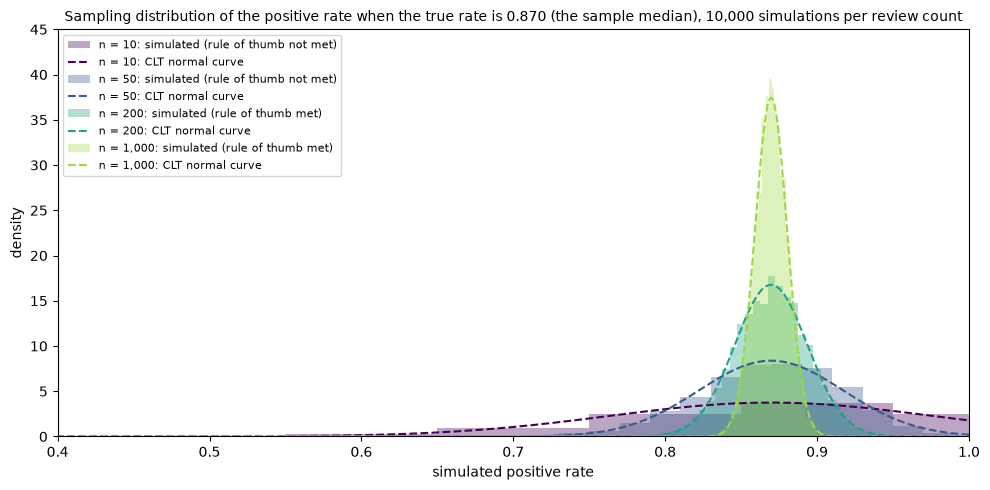

,clt_standard_error,simulated_sd,simulated_skew,normal_curve_share_above_1,rule_of_thumb_met
reviews,,,,,
10,0.1065,0.1068,-0.7395,0.1105,False
50,0.0476,0.0479,-0.3177,0.0031,False
200,0.0238,0.0239,-0.1232,0.0000,True
1000,0.0106,0.0107,-0.0520,0.0000,True


In [3]:
P_MEDIAN = float(games["raw_rate"].median())
SIM_N = [10, 50, 200, 1000]
DRAWS = 10_000

fig, ax = plt.subplots(figsize=(10, 5))
x = np.linspace(0, 1, 1001)
clt_rows = []
for n, colour in zip(SIM_N, plt.cm.viridis(np.linspace(0, 0.85, len(SIM_N)))):
    p_hat = rng.binomial(n, P_MEDIAN, DRAWS) / n
    se = np.sqrt(P_MEDIAN * (1 - P_MEDIAN) / n)
    ok = n * P_MEDIAN >= 10 and n * (1 - P_MEDIAN) >= 10
    bins = np.arange(-0.5, n + 1.5) / n   # one bin per possible rate k/n
    ax.hist(p_hat, bins=bins, density=True, histtype="stepfilled", color=colour, alpha=0.35,
            label=f"n = {n:,}: simulated (rule of thumb {'met' if ok else 'not met'})")
    ax.plot(x, stats.norm.pdf(x, P_MEDIAN, se), color=colour, linewidth=1.5, linestyle="--", label=f"n = {n:,}: CLT normal curve")
    clt_rows.append({"reviews": n, "clt_standard_error": se, "simulated_sd": p_hat.std(), "simulated_skew": stats.skew(p_hat),
                     "normal_curve_share_above_1": 1 - stats.norm.cdf(1, P_MEDIAN, se), "rule_of_thumb_met": ok})
ax.set_xlim(0.4, 1); ax.set_ylim(0, 45)
ax.set_xlabel("simulated positive rate"); ax.set_ylabel("density")
ax.set_title(f"Sampling distribution of the positive rate when the true rate is {P_MEDIAN:.3f} (the sample median), "
             f"{DRAWS:,} simulations per review count", fontsize=10)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
save_fig(fig, "06_aq5_clt_sampling_distribution")
plt.show()
clt = pd.DataFrame(clt_rows).set_index("reviews")
clt.to_csv(config.TABLES / "06_aq5_clt_check.csv")
clt.round(4)

### Interpretation: The central limit theorem check
**Author**: 
<!-- Compare the simulated distributions with the normal curves. Say at which review counts the normal approximation looks reasonable and where it fails (skew, the curve putting probability above a rate of 1), whether the simulated SD matches the CLT standard error, and what this means for using the textbook interval on games with few reviews. -->

In [4]:
MARGINS = [0.10, 0.05, 0.02]
rows = []
for p in [0.5, P_MEDIAN]:
    for e in MARGINS:
        n_needed = int(np.ceil(1.96 ** 2 * p * (1 - p) / e ** 2))
        rows.append({"assumed_rate": round(p, 3), "margin_of_error": e, "reviews_needed": n_needed,
                     "games_with_at_least_that_many": int((games["n"] >= n_needed).sum()),
                     "share_of_games": (games["n"] >= n_needed).mean()})
needed = pd.DataFrame(rows)
needed.to_csv(config.TABLES / "06_aq5_reviews_needed.csv", index=False)
print("A rate of 0.5 needs the most reviews for a given margin, so it is the worst case.")
needed.round(3)

A rate of 0.5 needs the most reviews for a given margin, so it is the worst case.


,assumed_rate,margin_of_error,reviews_needed,games_with_at_least_that_many,share_of_games
0,0.50,0.10,97,3928,0.764
1,0.50,0.05,385,2498,0.486
2,0.50,0.02,2401,1106,0.215
3,0.87,0.10,44,4573,0.889
4,0.87,0.05,175,3339,0.649
5,0.87,0.02,1089,1611,0.313


### Interpretation: Reviews needed for a given margin of error
**Author**: 
<!-- Using the table, say how many reviews a game needs for its positive rate to be within 10, 5 and 2 percentage points of the true rate (95% confidence), at the worst case and at the median rate, and what share of games in the sample reach each level. -->

## 3. How precise is one game's rate? Confidence intervals
*Code: Generated by AI Assistant*

*Written by AI Assistant*: section 2 gives the textbook 95% confidence interval $\hat p \pm 1.96\sqrt{\hat p(1-\hat p)/n}$. It relies on the normal approximation, and section 2 showed that approximation breaks down when a rate is high and $n$ is small: the interval can run past 1. The Wilson interval is a standard alternative that stays between 0 and 1 and behaves well at small $n$, so it is used for every game here. The table compares the two intervals by review band, including how many textbook intervals run past 1.

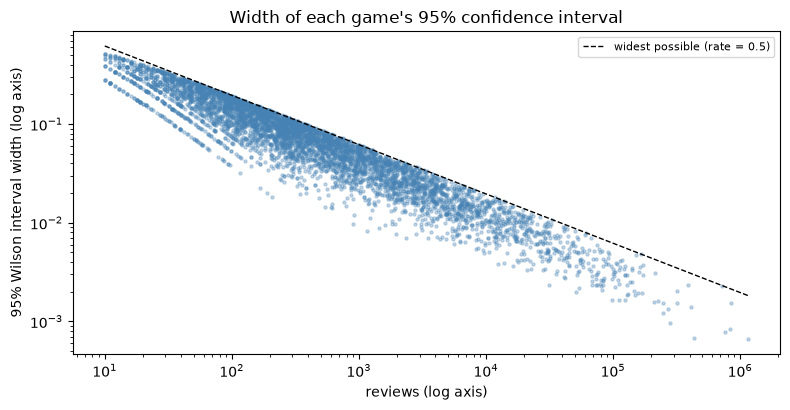

,games,median_wilson_width,median_textbook_width,textbook_intervals_above_1,share_textbook_above_1
band,,,,,
10-49,666,0.258,0.253,228,0.342
50-199,1274,0.134,0.134,107,0.084
200-999,1521,0.064,0.064,12,0.008
"1,000-9,999",1226,0.023,0.023,0,0.000
"10,000+",457,0.007,0.007,0,0.000


In [5]:
games["wilson_low"], games["wilson_high"] = proportion_confint(games["k"], games["n"], alpha=0.05, method="wilson")
games["wilson_width"] = games["wilson_high"] - games["wilson_low"]
textbook_half = 1.96 * np.sqrt(games["raw_rate"] * (1 - games["raw_rate"]) / games["n"])
games["textbook_width"] = 2 * textbook_half
games["textbook_above_1"] = games["raw_rate"] + textbook_half > 1

ci_table = games.groupby("band", observed=True).agg(
    games=("n", "size"), median_wilson_width=("wilson_width", "median"), median_textbook_width=("textbook_width", "median"),
    textbook_intervals_above_1=("textbook_above_1", "sum"))
ci_table["share_textbook_above_1"] = ci_table["textbook_intervals_above_1"] / ci_table["games"]
ci_table.to_csv(config.TABLES / "06_aq5_interval_width_by_band.csv")

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.scatter(games["n"], games["wilson_width"], s=5, alpha=0.3, color="steelblue")
grid = np.logspace(np.log10(MIN_REVIEWS), np.log10(games["n"].max()), 100)
ax.plot(grid, 2 * 1.96 * np.sqrt(0.25 / grid), color="black", linestyle="--", linewidth=1, label="widest possible (rate = 0.5)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("reviews (log axis)"); ax.set_ylabel("95% Wilson interval width (log axis)")
ax.set_title("Width of each game's 95% confidence interval"); ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "06_aq5_wilson_width")
plt.show()
ci_table.round(3)

### Interpretation: Confidence intervals for one game
**Author**: 
<!-- Describe how wide a game's 95% interval is in each review band, and how the Wilson and textbook intervals compare. Say how many textbook intervals run past a rate of 1 and in which bands, and link this to the CLT check in section 2. -->

### Precision by review band
*Code: Generated by AI Assistant, adapted from Diya Mabel Francis's AQ5 notebook (Wilson interval width by review band)*

*Written by AI Assistant*: the median 95% Wilson interval width in each review band from the table above, as a bar chart. Each bar is labelled with its width, and each band with its game count. The width narrows roughly with the square root of the review count, as the standard error formula in section 2 says, so the bars show how wide the sampling uncertainty is in each band, not a property of the games.

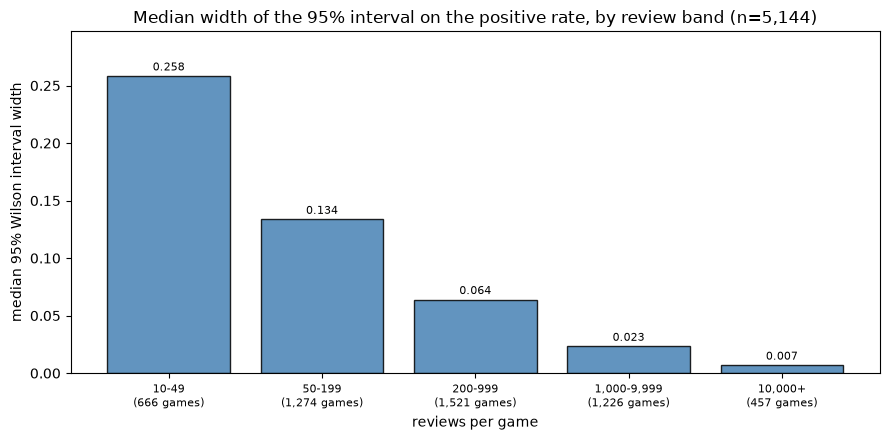

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.bar(range(len(ci_table)), ci_table["median_wilson_width"], color="steelblue", edgecolor="black", alpha=0.85)
ax.bar_label(bars, labels=[f"{w:.3f}" for w in ci_table["median_wilson_width"]], fontsize=8, padding=2)
ax.set_xticks(range(len(ci_table)))
ax.set_xticklabels([f"{b}\n({g:,} games)" for b, g in zip(ci_table.index, ci_table["games"])], fontsize=8)
ax.set_xlabel("reviews per game"); ax.set_ylabel("median 95% Wilson interval width")
ax.set_ylim(0, ci_table["median_wilson_width"].max() * 1.15)
ax.set_title(f"Median width of the 95% interval on the positive rate, by review band (n={len(games):,})")
plt.tight_layout()
save_fig(fig, "06_aq5_wilson_width_by_band")
plt.show()

### Interpretation: Precision by review band
**Author**: 
<!-- Using the bar chart, say how wide the interval on a game's positive rate typically is in each review band, in percentage points, and what that width means for reading a single game's rate. Note that the bands also differ in game age and audience size. -->

## 4. Can two games' rates be told apart? Two-proportion z-test
*Code: Generated by AI Assistant*

*Written by AI Assistant*: the two-proportion z-test asks whether two games' true positive rates differ, given their observed rates. Under the null hypothesis that both share one rate, the pooled rate is $\bar p = (k_1 + k_2)/(n_1 + n_2)$ and

$$z = \frac{\hat p_1 - \hat p_2}{\sqrt{\bar p(1-\bar p)\left(\frac{1}{n_1} + \frac{1}{n_2}\right)}}.$$

The test relies on the normal approximation from section 2, so it is only trustworthy when each game meets the rule of thumb. The first cell turns the formula around: for two games with the same number of reviews and rates near the sample median, it gives the smallest difference in rates that would be significant at the 5% level. The second cell tests two pairs of real games from the data, each pair about 10 points apart: one pair from the lowest review band and one from the 1,000 to 9,999 band. Each pair is chosen by rule, not by looking at results: the game closest to its band's median rate, and the game in the same band closest to 10 points below it.

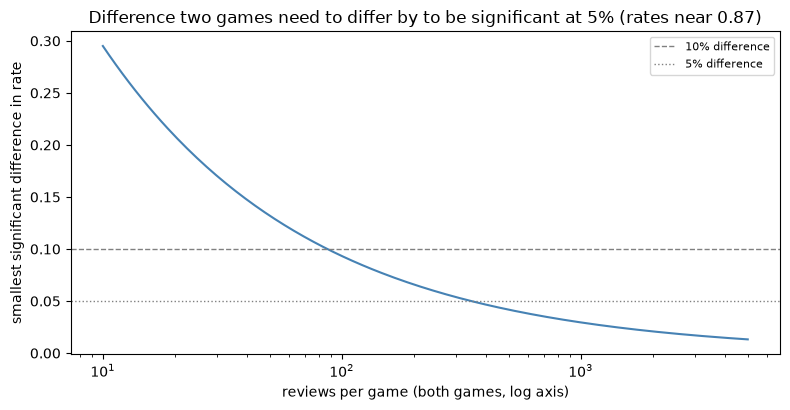

,smallest_significant_difference,rule_of_thumb_met
reviews_each,,
10,0.295,False
25,0.187,False
50,0.132,False
100,0.093,True
200,0.066,True
500,0.042,True
1000,0.030,True
5000,0.013,True


In [7]:
rows = []
for n in [10, 25, 50, 100, 200, 500, 1000, 5000]:
    rows.append({"reviews_each": n, "smallest_significant_difference": 1.96 * np.sqrt(2 * P_MEDIAN * (1 - P_MEDIAN) / n),
                 "rule_of_thumb_met": n * (1 - P_MEDIAN) >= 10})
detect = pd.DataFrame(rows).set_index("reviews_each")
detect.to_csv(config.TABLES / "06_aq5_detectable_difference.csv")

fig, ax = plt.subplots(figsize=(8, 4.2))
grid_n = np.logspace(1, np.log10(5000), 200)
ax.plot(grid_n, 1.96 * np.sqrt(2 * P_MEDIAN * (1 - P_MEDIAN) / grid_n), color="steelblue")
for d, style in [(0.10, "--"), (0.05, ":")]:
    ax.axhline(d, color="grey", linestyle=style, linewidth=1, label=f"{d:.0%} difference")
ax.set_xscale("log"); ax.set_xlabel("reviews per game (both games, log axis)")
ax.set_ylabel("smallest significant difference in rate")
ax.set_title(f"Difference two games need to differ by to be significant at 5% (rates near {P_MEDIAN:.2f})")
ax.legend(fontsize=8)
plt.tight_layout()
save_fig(fig, "06_aq5_detectable_difference")
plt.show()
detect.round(3)

### Interpretation: The smallest difference a z-test can detect
**Author**: 
<!-- Say how far apart two games' positive rates must be before a z-test calls the difference significant, at each review count in the table, and at what review count a 5 or 10 point difference becomes detectable. Note where the rule of thumb for the normal approximation is not met. -->

In [8]:
def pick_pair(band):
    pool = games[games["band"] == band]
    a = pool.iloc[(pool["raw_rate"] - pool["raw_rate"].median()).abs().argsort(kind="stable")].iloc[0]
    rest = pool.drop(index=a.name)
    b = rest.iloc[(rest["raw_rate"] - (a["raw_rate"] - 0.10)).abs().argsort(kind="stable")].iloc[0]
    return a, b

rows = []
for band in [BAND_LABELS[0], "1,000-9,999"]:
    a, b = pick_pair(band)
    z, p = proportions_ztest([a["k"], b["k"]], [a["n"], b["n"]])
    pooled = (a["k"] + b["k"]) / (a["n"] + b["n"])
    rows.append({
        "band": band,
        "game_1": a["steam_name"], "reviews_1": a["n"], "rate_1": a["raw_rate"], "wilson_1": f"{a['wilson_low']:.3f} to {a['wilson_high']:.3f}",
        "game_2": b["steam_name"], "reviews_2": b["n"], "rate_2": b["raw_rate"], "wilson_2": f"{b['wilson_low']:.3f} to {b['wilson_high']:.3f}",
        "difference": a["raw_rate"] - b["raw_rate"], "z": z, "p_value": p,
        "rule_of_thumb_met": min(a["n"], b["n"]) * min(pooled, 1 - pooled) >= 10,
    })
ztests = pd.DataFrame(rows).set_index("band")
ztests.to_csv(config.TABLES / "06_aq5_ztest_examples.csv")
ztests.T

band,10-49,"1,000-9,999"
game_1,Divine Favor,Alicemare
reviews_1,21,1122
rate_1,0.857143,0.885027
wilson_1,0.654 to 0.950,0.865 to 0.902
game_2,Bad Dream: Purgatory,Sherlock Holmes Chapter One
reviews_2,33,3658
rate_2,0.757576,0.785402
wilson_2,0.590 to 0.872,0.772 to 0.798
difference,0.099567,0.099625
z,0.885623,7.423283


### Interpretation: Two-proportion z-tests on real games
**Author**: 
<!-- For each pair, report the two rates, their difference, the z statistic and p-value, and whether the two Wilson intervals overlap. Compare the low-review pair with the high-review pair: a similar difference in rates, but different evidence behind it. Note whether the rule of thumb for the normal approximation is met. -->

## 5. How much of the spread between games is sampling noise?
*Code: Generated by AI Assistant*

*Written by AI Assistant*: section 3 looked at one game and section 4 at a pair. This section looks at every game in a band at once. Section 4 showed that a gap between two low-review games can be pure sampling noise. Across a whole band, the same question becomes: how much of the spread in rates between games is noise, and how much is real difference between games?

Within a review band, raw rates differ between games for two reasons: the games really differ, and each rate carries sampling noise. If the two are independent, their variances add:

$$\text{observed variance} = \text{variance of true rates} + \text{average sampling variance},$$

where a game's sampling variance is $SE^2 = \hat p(1-\hat p)/n$ from section 2. The noise share is the average sampling variance divided by the observed variance. The implied true-rate SD is the square root of what remains, set to 0 when the difference is negative. Sampling variance shrinks with $n$ by formula, so a smaller observed spread in high-review bands is expected; the implied true-rate SD is the part the formula does not explain.

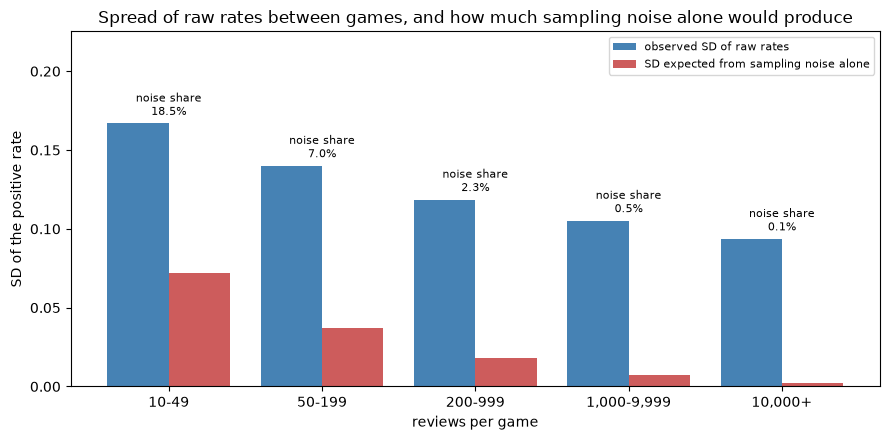

,games,observed_var,mean_sampling_var,noise_share,observed_sd,sampling_sd,implied_true_sd
band,,,,,,,
10-49,666,0.0279,0.0052,0.1854,0.1669,0.0719,0.1506
50-199,1274,0.0196,0.0014,0.0699,0.1400,0.0370,0.1351
200-999,1521,0.0141,0.0003,0.0231,0.1186,0.0180,0.1172
"1,000-9,999",1226,0.0111,0.0001,0.0046,0.1052,0.0071,0.1050
"10,000+",457,0.0088,0.0000,0.0005,0.0936,0.0021,0.0936


In [9]:
noise = games.assign(sampling_var=games["raw_rate"] * (1 - games["raw_rate"]) / games["n"]).groupby("band", observed=True).agg(
    games=("n", "size"), observed_var=("raw_rate", "var"), mean_sampling_var=("sampling_var", "mean"))
noise["noise_share"] = noise["mean_sampling_var"] / noise["observed_var"]
noise["observed_sd"] = np.sqrt(noise["observed_var"])
noise["sampling_sd"] = np.sqrt(noise["mean_sampling_var"])
noise["implied_true_sd"] = np.sqrt((noise["observed_var"] - noise["mean_sampling_var"]).clip(lower=0))
noise.to_csv(config.TABLES / "06_aq5_noise_share.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(noise))
ax.bar(x - 0.2, noise["observed_sd"], width=0.4, color="steelblue", label="observed SD of raw rates")
ax.bar(x + 0.2, noise["sampling_sd"], width=0.4, color="indianred", label="SD expected from sampling noise alone")
for xi, h, s in zip(x, noise["observed_sd"], noise["noise_share"]):
    ax.text(xi, h + 0.003, f"noise share\n{s:.1%}", ha="center", va="bottom", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(noise.index)
ax.set_ylim(0, noise["observed_sd"].max() * 1.35)
ax.set_xlabel("reviews per game"); ax.set_ylabel("SD of the positive rate")
ax.set_title("Spread of raw rates between games, and how much sampling noise alone would produce")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
save_fig(fig, "06_aq5_noise_share")
plt.show()
noise.round(4)

### Interpretation: Sampling noise in the spread between games
**Author**: 
<!-- Say what share of the spread in raw rates between games is sampling noise in each review band, and how the implied spread of true rates compares across bands. Say what this means for ranking or comparing games in the low bands against the high ones. -->

## 6. Does the mean rate differ by review count? ANOVA
*Code: Generated by AI Assistant*

*Written by AI Assistant*: sections 2 to 5 are about precision: sampling noise makes a rate with few reviews less certain, but it does not push the rate up or down, because $\hat p$ is an unbiased estimate of $p$. So nothing in the sampling arithmetic says that games with more reviews should have a higher or lower mean rate. This section tests whether they do. The review bands from section 1 are the groups. Three tests are run, each answering a different question:

| Test | Question | Effect size |
|---|---|---|
| Welch's ANOVA, with Games-Howell pairwise comparisons | Does the mean rate differ between bands? | $\omega^2$, Hedges' g per pair |
| Kruskal-Wallis | Do the bands differ in rank, without assuming normality? | $\varepsilon^2$ |
| Two-way ANOVA, review band, game-age group and their interaction | Does the band difference remain once game age is accounted for, and does it depend on age? | partial $\eta^2$ |

Classic one-way ANOVA assumes every group has the same variance. Section 5 shows the spread shrinks as reviews rise, so the variances are not equal and Welch's ANOVA, which does not assume equal variances, is used, with Games-Howell as its post-hoc test instead of Tukey. Positive rates are bounded at 1 and skewed, so Kruskal-Wallis is reported as a check. Review counts grow with a game's age, so the two-way ANOVA adds four age groups (1 to 2, 3 to 5, 6 to 9, and 10 or more years since release) and the band by age interaction, which tests whether the band pattern differs between age groups. Its F tests use Type II sums of squares and are heteroscedasticity-robust (HC3). All three tests treat games as independent. Games by the same developer are not, which these tests cannot account for.

In [10]:
groups = [g["raw_rate"].to_numpy() for _, g in games.groupby("band", observed=True)]
N, k = len(games), len(groups)

welch = pg.welch_anova(data=games, dv="raw_rate", between="band")
kruskal = stats.kruskal(*groups)

grand = games["raw_rate"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_within = sum(((g - g.mean()) ** 2).sum() for g in groups)
ms_within = ss_within / (N - k)
omega_sq = (ss_between - (k - 1) * ms_within) / (ss_between + ss_within + ms_within)

tests = pd.DataFrame([
    {"test": "Welch's ANOVA", "statistic": float(welch["F"].iloc[0]), "df": f"{k - 1}, {float(welch['ddof2'].iloc[0]):.1f}",
     "p_value": float(welch["p_unc"].iloc[0] if "p_unc" in welch else welch["p-unc"].iloc[0]), "effect_size": omega_sq, "effect_measure": "omega squared"},
    {"test": "Kruskal-Wallis", "statistic": kruskal.statistic, "df": f"{k - 1}", "p_value": kruskal.pvalue,
     "effect_size": kruskal.statistic / (N - 1), "effect_measure": "epsilon squared"},
]).set_index("test")
tests.to_csv(config.TABLES / "06_aq5_anova_tests.csv")
print(f"games: {N:,} in {k} review bands")
display(tests)

gh = pg.pairwise_gameshowell(data=games, dv="raw_rate", between="band")
gh.to_csv(config.TABLES / "06_aq5_games_howell.csv", index=False)
gh.round(4)

games: 5,144 in 5 review bands


,statistic,df,p_value,effect_size,effect_measure
test,,,,,
Welch's ANOVA,49.590068,"4, 1925.3",9.174410e-40,0.031022,omega squared
Kruskal-Wallis,133.925229,4,5.633472e-28,0.026040,epsilon squared


,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges
0,10-49,50-199,0.8092,0.8132,-0.0039,0.0076,-0.5193,1162.4449,0.9854,-0.0262
1,10-49,200-999,0.8092,0.8343,-0.0251,0.0071,-3.5134,970.8061,0.0042,-0.1857
2,10-49,"1,000-9,999",0.8092,0.8574,-0.0481,0.0071,-6.7519,958.8492,0.0000,-0.3694
3,10-49,"10,000+",0.8092,0.8828,-0.0735,0.0078,-9.4157,1082.8134,0.0000,-0.5185
4,50-199,200-999,0.8132,0.8343,-0.0212,0.0050,-4.2663,2504.6488,0.0002,-0.1644
5,50-199,"1,000-9,999",0.8132,0.8574,-0.0442,0.0049,-8.9474,2360.2977,0.0000,-0.3559
6,50-199,"10,000+",0.8132,0.8828,-0.0696,0.0059,-11.8378,1203.6753,0.0000,-0.5376
7,200-999,"1,000-9,999",0.8343,0.8574,-0.0230,0.0043,-5.3896,2719.8940,0.0000,-0.2042
8,200-999,"10,000+",0.8343,0.8828,-0.0484,0.0053,-9.0836,936.1172,0.0000,-0.4273
9,"1,000-9,999","10,000+",0.8574,0.8828,-0.0254,0.0053,-4.7813,910.9457,0.0000,-0.2484


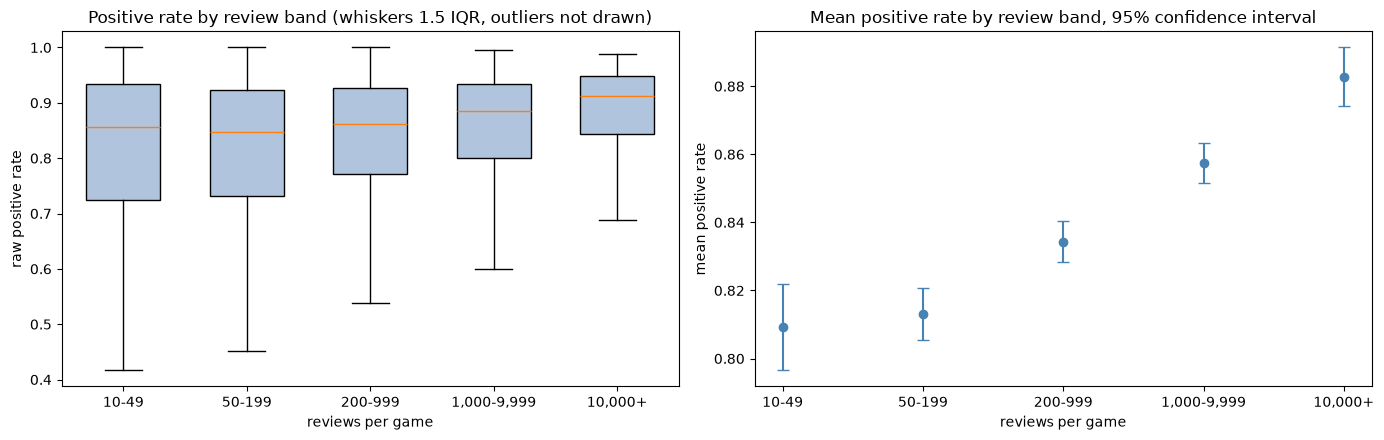

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
data = [g["raw_rate"].to_numpy() for _, g in games.groupby("band", observed=True)]
axes[0].boxplot(data, showfliers=False, widths=0.6, patch_artist=True, boxprops={"facecolor": "lightsteelblue"})
axes[0].set_xticks(range(1, len(BAND_LABELS) + 1)); axes[0].set_xticklabels(BAND_LABELS)
axes[0].set_xlabel("reviews per game"); axes[0].set_ylabel("raw positive rate")
axes[0].set_title("Positive rate by review band (whiskers 1.5 IQR, outliers not drawn)")

ci = games.groupby("band", observed=True)["raw_rate"].agg(["mean", "std", "size"])
ci["half"] = stats.t.ppf(0.975, ci["size"] - 1) * ci["std"] / np.sqrt(ci["size"])
axes[1].errorbar(range(len(ci)), ci["mean"], yerr=ci["half"], fmt="o", capsize=4, color="steelblue")
axes[1].set_xticks(range(len(ci))); axes[1].set_xticklabels(ci.index)
axes[1].set_xlabel("reviews per game"); axes[1].set_ylabel("mean positive rate")
axes[1].set_title("Mean positive rate by review band, 95% confidence interval")
plt.tight_layout()
save_fig(fig, "06_aq5_rate_by_band")
plt.show()

### Interpretation: One-way tests across review bands
**Author**: 
<!-- Report each test with its statistic, p-value and effect size. Say whether the mean rate differs between bands, how large that difference is in practical terms (omega squared, and the Games-Howell differences in percentage points), and whether Kruskal-Wallis agrees. A small p-value with a small effect size is possible with this many games. -->

years since release,1-2,3-5,6-9,10+,All
review band,,,,,
10-49,151,259,225,31,666
50-199,243,452,410,169,1274
200-999,258,432,534,297,1521
"1,000-9,999",139,371,409,307,1226
"10,000+",38,106,130,183,457
All,829,1620,1708,987,5144


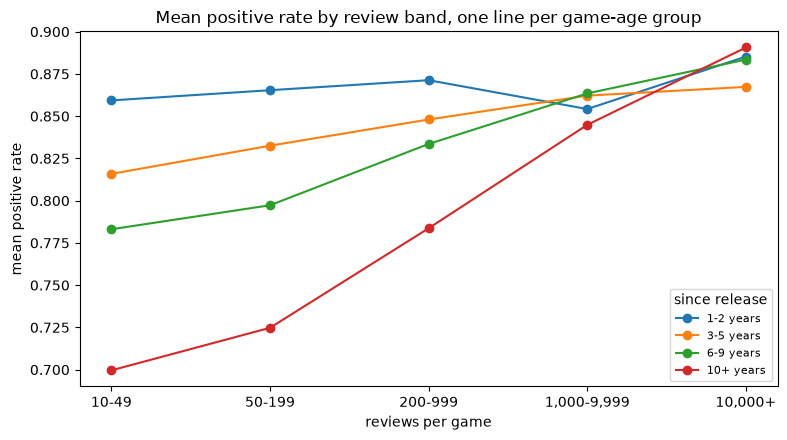

,sum_sq,df,F,PR(>F),partial_eta_sq
C(band),4.4085,4.0,72.4553,0.0,0.0535
C(age_group),2.0313,3.0,44.5138,0.0,0.0254
C(band):C(age_group),1.7846,12.0,9.7766,0.0,0.0224
Residual,77.9415,5124.0,NaN,NaN,NaN


In [12]:
games["age_group"] = pd.cut(games["steam_years_since_release"], [0, 2, 5, 9, np.inf], labels=["1-2", "3-5", "6-9", "10+"])
display(pd.crosstab(games["band"], games["age_group"], margins=True).rename_axis(index="review band", columns="years since release"))

two_way = smf.ols("raw_rate ~ C(band) * C(age_group)", data=games).fit()
aov = anova_lm(two_way, typ=2, robust="hc3")
aov["partial_eta_sq"] = aov["sum_sq"] / (aov["sum_sq"] + aov.loc["Residual", "sum_sq"])
aov.loc["Residual", "partial_eta_sq"] = np.nan
aov.to_csv(config.TABLES / "06_aq5_two_way_anova.csv")

cell_means = games.pivot_table(index="age_group", columns="band", values="raw_rate", aggfunc="mean", observed=True)
fig, ax = plt.subplots(figsize=(8, 4.5))
for age, row in cell_means.iterrows():
    ax.plot(range(len(row)), row.to_numpy(), marker="o", label=f"{age} years")
ax.set_xticks(range(len(cell_means.columns))); ax.set_xticklabels(cell_means.columns)
ax.set_xlabel("reviews per game"); ax.set_ylabel("mean positive rate")
ax.set_title("Mean positive rate by review band, one line per game-age group"); ax.legend(fontsize=8, title="since release")
plt.tight_layout()
save_fig(fig, "06_aq5_rate_by_band_and_age")
plt.show()
aov.round(4)

### Interpretation: Two-way ANOVA with game age
**Author**: 
<!-- Say whether the difference in mean rate between review bands remains once game age is in the model, using the F test, p-value and partial eta squared for each factor. Use the interaction test and the line chart to say whether the band pattern differs between age groups, and in which ones. Note that games by the same developer are not independent. -->

## 7. Answer to AQ5
*Written by AI Assistant*: this cell is for the group's answer. It draws on every section above.

### Interpretation: How does the number of player reviews affect the reliability of estimated player reception? (AQ5)
**Author**: 
<!-- This is the answer to AQ5. Using sections 2 to 6, say how the number of reviews affects how far a game's positive rate can be trusted: the margin of error and the reviews needed for a given precision, how wide the confidence intervals are by band, how large a difference between two games must be to be detected, and how much of the spread between games is noise. Then say whether games with more reviews also differ in their rate itself, once game age is accounted for, and what that means for comparing games with few and many reviews. State the limits: reviewers choose to review, games by one developer are not independent, and the sample is story-driven games matched to HowLongToBeat. -->

## Outputs
*Code: Generated by AI Assistant*

In [13]:
print(f"rows: {len(df):,} in, {len(games):,} in the reception sample; no rows saved for later stages")
print(f"figures: {sorted(p.name for p in config.FIGURES.glob('06_aq5_*.png'))}")
print(f"tables : {sorted(p.name for p in config.TABLES.glob('06_aq5_*.csv'))}")

rows: 5,281 in, 5,144 in the reception sample; no rows saved for later stages
figures: ['06_aq5_clt_sampling_distribution.png', '06_aq5_detectable_difference.png', '06_aq5_noise_share.png', '06_aq5_rate_by_band.png', '06_aq5_rate_by_band_and_age.png', '06_aq5_raw_rate_by_reviews.png', '06_aq5_wilson_width.png', '06_aq5_wilson_width_by_band.png']
tables : ['06_aq5_anova_tests.csv', '06_aq5_clt_check.csv', '06_aq5_detectable_difference.csv', '06_aq5_games_howell.csv', '06_aq5_interval_width_by_band.csv', '06_aq5_noise_share.csv', '06_aq5_raw_rate_by_band.csv', '06_aq5_reviews_needed.csv', '06_aq5_two_way_anova.csv', '06_aq5_ztest_examples.csv']
